# Thesaurus Experiments

This notebook explores the Schleiermacher thesaurus data:
- **14 topics** (collections)
- **256 words and concepts**

Data sources:
- `data/Thesaurus/thesaurus.ttl` (Turtle/RDF format)
- `data/Thesaurus/aesthetik-vl_thesaurus.xml` (SKOS/XML format)

## 1. Install Requirements

In [1]:
# Install required packages for RDF/SKOS processing
%pip install rdflib lxml pandas matplotlib seaborn

   ---------------------------------------- 0.0/565.4 kB ? eta -:--:--
   ------------------ --------------------- 262.1/565.4 kB ? eta -:--:--
   ---------------------------------------- 565.4/565.4 kB 1.6 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 25.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Import Libraries

In [2]:
import rdflib
from rdflib import Graph, Namespace, RDF, SKOS
from lxml import etree
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from collections import defaultdict

# Set style for plots
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

## 3. Load Thesaurus Data from TTL (Turtle/RDF)

In [3]:
# Define paths
data_dir = Path("../data/Thesaurus")
ttl_file = data_dir / "thesaurus.ttl"
xml_file = data_dir / "aesthetik-vl_thesaurus.xml"

# Load TTL file
g = Graph()
g.parse(ttl_file, format="turtle")

print(f"Loaded {len(g)} triples from {ttl_file.name}")

# Define namespaces
SKOS = Namespace("http://www.w3.org/2004/02/skos/core#")
SCHLEIERMACHER = Namespace("https://schleiermacher-digital.de/skos/")

# Extract collections (topics)
collections = list(g.subjects(RDF.type, SKOS.Collection))
print(f"\nFound {len(collections)} collections (topics)")

# Extract concepts (terms)
concepts = list(g.subjects(RDF.type, SKOS.Concept))
print(f"Found {len(concepts)} concepts (terms)")

Loaded 2556 triples from thesaurus.ttl

Found 2 collections (topics)
Found 271 concepts (terms)


## 4. Extract Topics and Terms Structure

In [4]:
# Build a dictionary of concepts with their labels
concept_data = []

for concept in concepts:
    # Get preferred label
    pref_labels = list(g.objects(concept, SKOS.prefLabel))
    pref_label = str(pref_labels[0]) if pref_labels else None
    
    # Get alternative labels
    alt_labels = [str(label) for label in g.objects(concept, SKOS.altLabel)]
    
    # Get broader concepts
    broader = [str(b) for b in g.objects(concept, SKOS.broader)]
    
    # Get narrower concepts
    narrower = [str(n) for n in g.objects(concept, SKOS.narrower)]
    
    # Get related concepts
    related = [str(r) for r in g.objects(concept, SKOS.related)]
    
    concept_data.append({
        'uri': str(concept),
        'prefLabel': pref_label,
        'altLabels': alt_labels,
        'broader': broader,
        'narrower': narrower,
        'related': related,
        'num_broader': len(broader),
        'num_narrower': len(narrower),
        'num_related': len(related)
    })

# Create DataFrame
df_concepts = pd.DataFrame(concept_data)
print(f"Created DataFrame with {len(df_concepts)} concepts")
print(f"\nSample concepts:")
df_concepts[['uri', 'prefLabel', 'num_broader', 'num_narrower', 'num_related']].head(10)

Created DataFrame with 271 concepts

Sample concepts:


,uri,prefLabel,num_broader,num_narrower,num_related
0,https://schleiermacher-digital.de/skos/S9478146,Zeichen,1,0,0
1,https://schleiermacher-digital.de/skos/S0720661,Kunstvermögen,1,0,0
2,https://schleiermacher-digital.de/skos/S3786610,natürlich,1,0,0
3,https://schleiermacher-digital.de/skos/S4818188,populär,1,0,0
4,https://schleiermacher-digital.de/skos/S5660592,Welt,1,0,0
5,https://schleiermacher-digital.de/skos/S7595267,Nichtigkeit,1,0,0
6,https://schleiermacher-digital.de/skos/S8002896,Symbolische,1,0,0
7,https://schleiermacher-digital.de/skos/S8192133,pathema,1,0,0
8,https://schleiermacher-digital.de/skos/S9356778,symbolisch,1,0,0
9,https://schleiermacher-digital.de/skos/S9439407,Ebenbild,1,0,0


## 5. Alternative: Load from XML (SKOS)

In [5]:
# Parse XML file
tree = etree.parse(str(xml_file))
root = tree.getroot()

# Define XML namespaces
namespaces = {
    'rdf': 'http://www.w3.org/1999/02/22-rdf-syntax-ns#',
    'skos': 'http://www.w3.org/2004/02/skos/core#',
    'telota': 'http://www.telota.de'
}

# Find all collections
xml_collections = root.findall('.//skos:Collection', namespaces)
print(f"Found {len(xml_collections)} collections in XML")

# Find all concepts
xml_concepts = root.findall('.//skos:Concept', namespaces)
print(f"Found {len(xml_concepts)} concepts in XML")

# Extract concept information from XML
xml_concept_data = []
for concept in xml_concepts:
    uri = concept.get('{http://www.w3.org/1999/02/22-rdf-syntax-ns#}about')
    
    # Get prefLabel
    pref_label_elem = concept.find('skos:prefLabel', namespaces)
    pref_label = pref_label_elem.text if pref_label_elem is not None else None
    
    # Get altLabels
    alt_labels = [elem.text for elem in concept.findall('skos:altLabel', namespaces)]
    
    xml_concept_data.append({
        'uri': uri,
        'prefLabel': pref_label,
        'altLabels': alt_labels,
        'num_altLabels': len(alt_labels)
    })

df_xml_concepts = pd.DataFrame(xml_concept_data)
print(f"\nCreated DataFrame with {len(df_xml_concepts)} concepts from XML")
print(f"\nSample concepts from XML:")
df_xml_concepts[['uri', 'prefLabel', 'num_altLabels']].head(10)

Found 2 collections in XML
Found 271 concepts in XML

Created DataFrame with 271 concepts from XML

Sample concepts from XML:


,uri,prefLabel,num_altLabels
0,https://schleiermacher-digital.de/skos/S9478260,Geschichte der Ästhetik,0
1,https://schleiermacher-digital.de/skos/S9478184,Kunst als Nachahmung der Natur,0
2,https://schleiermacher-digital.de/skos/S9478192,Zur Theorie der Kunst als freie Produktivität ...,0
3,https://schleiermacher-digital.de/skos/S9478262,Die Ethik der Kunst,0
4,https://schleiermacher-digital.de/skos/S9478268,Die Geschichtlichkeit der Kunst,0
5,https://schleiermacher-digital.de/skos/S9478209,Kunst und Religion,0
6,https://schleiermacher-digital.de/skos/S9478247,Poesie vs. Philosophie,0
7,https://schleiermacher-digital.de/skos/S9478288,Stilistik der Künste,0
8,https://schleiermacher-digital.de/skos/S9478196,Traum und Kunst,0
9,https://schleiermacher-digital.de/skos/S9478279,Identität und Differenz der Künste,0


## 6. Summary Statistics

In [6]:
print("=" * 60)
print("THESAURUS SUMMARY STATISTICS")
print("=" * 60)

print(f"\n📊 From TTL (Turtle/RDF):")
print(f"   Collections (Topics): {len(collections)}")
print(f"   Concepts (Terms): {len(concepts)}")
print(f"   Total Triples: {len(g)}")

print(f"\n📊 From XML (SKOS):")
print(f"   Collections: {len(xml_collections)}")
print(f"   Concepts: {len(xml_concepts)}")

print(f"\n📈 Concept Statistics (from TTL):")
print(f"   Concepts with broader terms: {(df_concepts['num_broader'] > 0).sum()}")
print(f"   Concepts with narrower terms: {(df_concepts['num_narrower'] > 0).sum()}")
print(f"   Concepts with related terms: {(df_concepts['num_related'] > 0).sum()}")
print(f"   Concepts with alt labels: {(df_concepts['altLabels'].str.len() > 0).sum()}")

print(f"\n📊 Relationship Counts:")
print(f"   Total broader relationships: {df_concepts['num_broader'].sum()}")
print(f"   Total narrower relationships: {df_concepts['num_narrower'].sum()}")
print(f"   Total related relationships: {df_concepts['num_related'].sum()}")

print(f"\n🏷️  Top 10 Most Connected Concepts:")
df_concepts['total_connections'] = df_concepts['num_broader'] + df_concepts['num_narrower'] + df_concepts['num_related']
top_connected = df_concepts.nlargest(10, 'total_connections')[['prefLabel', 'num_broader', 'num_narrower', 'num_related', 'total_connections']]
print(top_connected.to_string(index=False))

THESAURUS SUMMARY STATISTICS

📊 From TTL (Turtle/RDF):
   Collections (Topics): 2
   Concepts (Terms): 271
   Total Triples: 2556

📊 From XML (SKOS):
   Collections: 2
   Concepts: 271

📈 Concept Statistics (from TTL):
   Concepts with broader terms: 257
   Concepts with narrower terms: 14
   Concepts with related terms: 38
   Concepts with alt labels: 80

📊 Relationship Counts:
   Total broader relationships: 452
   Total narrower relationships: 453
   Total related relationships: 95

🏷️  Top 10 Most Connected Concepts:
                                                  prefLabel  num_broader  num_narrower  num_related  total_connections
Zur Theorie der Kunst als freie Produktivität des Künstlers            0            69           11                 80
                                        Die Ethik der Kunst            0            55            6                 61
                       Die Phasen der künstlerischen Praxis            0            45            7                 

## 7. Visualization: Concept Relationships

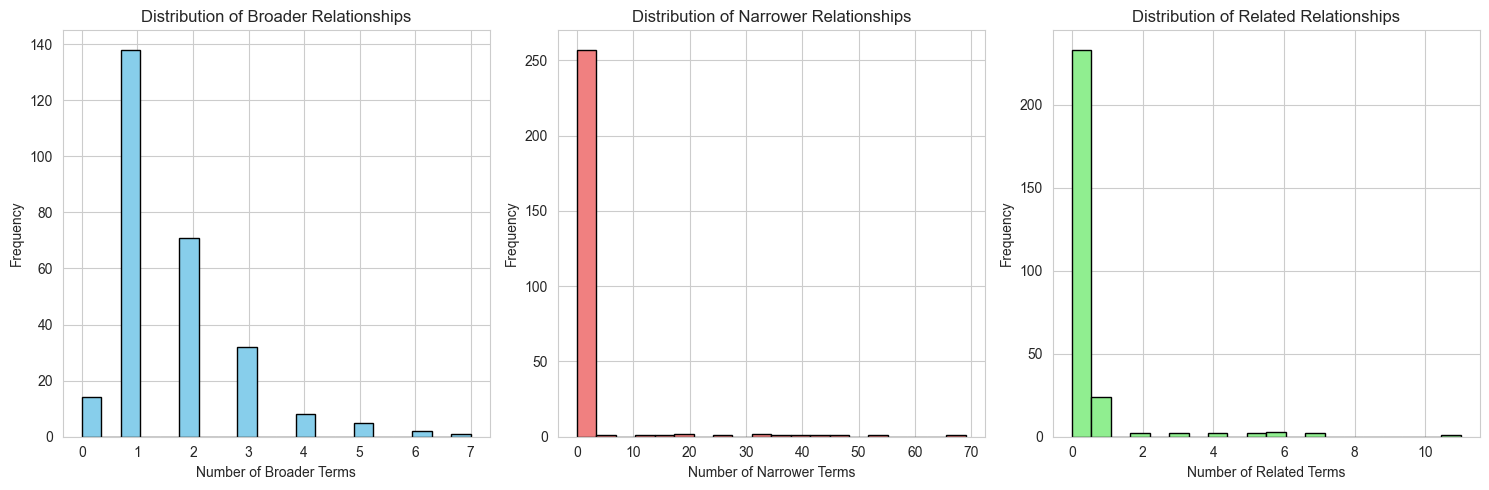

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Distribution of broader relationships
axes[0].hist(df_concepts['num_broader'], bins=20, color='skyblue', edgecolor='black')
axes[0].set_title('Distribution of Broader Relationships')
axes[0].set_xlabel('Number of Broader Terms')
axes[0].set_ylabel('Frequency')

# Distribution of narrower relationships
axes[1].hist(df_concepts['num_narrower'], bins=20, color='lightcoral', edgecolor='black')
axes[1].set_title('Distribution of Narrower Relationships')
axes[1].set_xlabel('Number of Narrower Terms')
axes[1].set_ylabel('Frequency')

# Distribution of related relationships
axes[2].hist(df_concepts['num_related'], bins=20, color='lightgreen', edgecolor='black')
axes[2].set_title('Distribution of Related Relationships')
axes[2].set_xlabel('Number of Related Terms')
axes[2].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

---
## 8. ChromaDB: Semantic Search with Embeddings

Now we'll create a ChromaDB collection with embeddings of thesaurus concepts, then use it to find semantic matches in letter texts.

### 8.1 Install ChromaDB and Embedding Dependencies

In [8]:
# Install ChromaDB and sentence transformers for embeddings
%pip install chromadb sentence-transformers

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 25.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [9]:
import chromadb
from chromadb.utils import embedding_functions

print(f"ChromaDB version: {chromadb.__version__}")

ChromaDB version: 1.1.1


### 8.2 Create ChromaDB Collection with Thesaurus Concepts

In [10]:
# Initialize ChromaDB client
chroma_client = chromadb.Client()

# Use a multilingual sentence transformer model (good for German text)
# Alternative models: "paraphrase-multilingual-MiniLM-L12-v2", "distiluse-base-multilingual-cased-v2"
embedding_function = embedding_functions.SentenceTransformerEmbeddingFunction(
    model_name="paraphrase-multilingual-mpnet-base-v2"
)

# Create or get collection
collection = chroma_client.get_or_create_collection(
    name="thesaurus_concepts",
    embedding_function=embedding_function,
    metadata={"description": "Schleiermacher thesaurus concepts and terms"}
)

print(f"Collection created: {collection.name}")
print(f"Current items in collection: {collection.count()}")

c:\Users\westphal\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`
Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


Collection created: thesaurus_concepts
Current items in collection: 0


In [ ]:
# Prepare documents for embedding
# We'll combine prefLabel with altLabels for richer semantic representation
documents = []
metadatas = []
ids = []

for idx, row in df_concepts.iterrows():
    # Create a rich text representation of the concept
    doc_parts = []
    
    if row['prefLabel']:
        doc_parts.append(row['prefLabel'])
    
    # Add alternative labels
    if row['altLabels']:
        doc_parts.extend(row['altLabels'])
    
    # Combine into single document
    document = " | ".join(doc_parts) if doc_parts else "Unknown concept"
    
    documents.append(document)
    
    # Store metadata
    metadatas.append({
        'uri': row['uri'],
        'prefLabel': row['prefLabel'] or '',
        'num_altLabels': len(row['altLabels']),
        'num_broader': row['num_broader'],
        'num_narrower': row['num_narrower'],
        'num_related': row['num_related']
    })
    
    # Use a simple ID based on index
    ids.append(f"concept_{idx}")

print(f"Prepared {len(documents)} documents for embedding")
print(f"\nExample documents:")
for i in range(min(5, len(documents))):
    print(f"  {i+1}. {documents[i][:100]}...")

In [ ]:
# Add documents to ChromaDB collection
# This will automatically create embeddings using the sentence transformer
collection.add(
    documents=documents,
    metadatas=metadatas,
    ids=ids
)

print(f"✅ Successfully added {collection.count()} concepts to ChromaDB collection")
print(f"📊 Collection stats: {collection.count()} items")

### 8.3 Load and Chunk Letters

In [ ]:
# TODO: Specify your letter data source
# For now, let's create a sample letter chunking function
# You can replace this with your actual letter loading code

def chunk_text(text, chunk_size=500, overlap=50):
    """
    Split text into overlapping chunks.
    
    Args:
        text: The text to chunk
        chunk_size: Maximum characters per chunk
        overlap: Number of characters to overlap between chunks
    
    Returns:
        List of text chunks
    """
    chunks = []
    start = 0
    
    while start < len(text):
        end = start + chunk_size
        chunk = text[start:end]
        
        # Try to break at sentence boundaries
        if end < len(text):
            # Look for last period, exclamation, or question mark
            last_break = max(
                chunk.rfind('.'),
                chunk.rfind('!'),
                chunk.rfind('?')
            )
            if last_break > chunk_size * 0.5:  # Only break if we're past halfway
                chunk = chunk[:last_break + 1]
                end = start + last_break + 1
        
        chunks.append(chunk.strip())
        start = end - overlap
    
    return chunks

# Example: Load a sample letter (replace with your actual data loading)
sample_letter = """
Dies ist ein Beispielbrief über Ästhetik und Philosophie. 
Der Brief behandelt verschiedene Themen der Kunst und Wissenschaft.
Es werden Konzepte wie Schönheit, Form und Inhalt diskutiert.
Die Bildung und das Verhältnis von Mensch und Natur stehen im Zentrum.
"""

chunks = chunk_text(sample_letter, chunk_size=200, overlap=30)
print(f"Created {len(chunks)} chunks from sample letter")
print(f"\nExample chunks:")
for i, chunk in enumerate(chunks, 1):
    print(f"  Chunk {i}: {chunk[:80]}...")

### 8.4 Query ChromaDB for Semantic Matches

In [ ]:
# Query the collection for each chunk
def find_concepts_in_chunk(chunk, n_results=5, distance_threshold=None):
    """
    Find the most semantically similar concepts for a text chunk.
    
    Args:
        chunk: Text chunk to query
        n_results: Number of top results to return
        distance_threshold: Optional threshold to filter results
    
    Returns:
        Query results from ChromaDB
    """
    results = collection.query(
        query_texts=[chunk],
        n_results=n_results
    )
    return results

# Test with the first chunk
if chunks:
    test_chunk = chunks[0]
    print(f"Query chunk:\n{test_chunk}\n")
    print("=" * 60)
    
    results = find_concepts_in_chunk(test_chunk, n_results=5)
    
    print(f"\n🔍 Top 5 semantically similar concepts:\n")
    for i, (doc, metadata, distance) in enumerate(zip(
        results['documents'][0],
        results['metadatas'][0], 
        results['distances'][0]
    ), 1):
        print(f"{i}. {metadata['prefLabel']}")
        print(f"   Distance: {distance:.4f}")
        print(f"   URI: {metadata['uri']}")
        print(f"   Document: {doc[:100]}...")
        print()

### 8.5 Batch Process Multiple Letter Chunks

In [ ]:
# Process all chunks and collect results
all_matches = []

for chunk_idx, chunk in enumerate(chunks):
    results = find_concepts_in_chunk(chunk, n_results=3)
    
    for doc, metadata, distance in zip(
        results['documents'][0],
        results['metadatas'][0],
        results['distances'][0]
    ):
        all_matches.append({
            'chunk_idx': chunk_idx,
            'chunk_text': chunk[:100] + '...',
            'concept_label': metadata['prefLabel'],
            'concept_uri': metadata['uri'],
            'similarity_distance': distance,
            'similarity_score': 1 - distance  # Convert distance to similarity score
        })

# Create DataFrame with results
df_matches = pd.DataFrame(all_matches)

print(f"Found {len(df_matches)} concept matches across {len(chunks)} chunks")
print(f"\nTop matches (lowest distance = highest similarity):")
df_matches.nsmallest(10, 'similarity_distance')[
    ['chunk_idx', 'concept_label', 'similarity_distance', 'similarity_score']
]

### 8.6 Visualize Concept Frequency in Letters

In [ ]:
# Count concept occurrences (with similarity threshold)
similarity_threshold = 0.5  # Only count matches with similarity > 0.5

high_confidence_matches = df_matches[df_matches['similarity_score'] > similarity_threshold]

concept_counts = high_confidence_matches['concept_label'].value_counts().head(15)

# Create bar plot
plt.figure(figsize=(12, 6))
concept_counts.plot(kind='barh', color='steelblue')
plt.title(f'Top 15 Most Frequently Matched Concepts\n(Similarity > {similarity_threshold})')
plt.xlabel('Number of Matches')
plt.ylabel('Concept')
plt.tight_layout()
plt.show()

print(f"\nTotal high-confidence matches: {len(high_confidence_matches)}")
print(f"Unique concepts matched: {high_confidence_matches['concept_label'].nunique()}")

### 8.7 Export Results

In [ ]:
# Save results to CSV
output_dir = Path("../output")
output_dir.mkdir(exist_ok=True)

results_file = output_dir / "thesaurus_concept_matches.csv"
df_matches.to_csv(results_file, index=False, encoding='utf-8')

print(f"✅ Results saved to: {results_file}")
print(f"📊 Total rows: {len(df_matches)}")

# Also save high-confidence matches separately
high_conf_file = output_dir / "thesaurus_concept_matches_high_confidence.csv"
high_confidence_matches.to_csv(high_conf_file, index=False, encoding='utf-8')

print(f"✅ High-confidence results saved to: {high_conf_file}")
print(f"📊 High-confidence rows: {len(high_confidence_matches)}")

---
## Next Steps

To use this workflow with your actual letter data:

1. **Load your letters**: Replace the sample letter in section 8.3 with code to load your actual letter XML/text files
2. **Adjust chunking strategy**: Tune `chunk_size` and `overlap` parameters based on your letter structure
3. **Fine-tune similarity threshold**: Experiment with different thresholds in section 8.6 to find optimal concept matching
4. **Process multiple letters**: Extend the code to iterate through your entire letter collection
5. **Analyze results**: Use the exported CSV files to analyze which concepts appear in which letters

### Customization Options:

- **Embedding model**: Try different multilingual models for better German text handling
- **Chunk size**: Smaller chunks (200-300 chars) for precise matching, larger chunks (500-1000 chars) for context
- **Number of results**: Adjust `n_results` parameter to get more or fewer concept matches per chunk
- **Metadata enrichment**: Add letter metadata (date, sender, recipient) to track concept usage over time